In [1]:
import sys
from pathlib import Path

# locate repo root
root = Path.cwd().resolve()
while root != root.parent and not (root / "shared").exists():
    root = root.parent

if not (root / "shared").exists():
    raise RuntimeError("Could not find project root containing 'shared/'")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from shared.paths import get_experiment_paths
from shared.visualization import show_grid, save_grid
from shared.seed import seed_everything
from shared.weight_init import dcgan_weights_init

seed_everything(42)

import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

paths = get_experiment_paths("10_face_does_not_exist")
paths


ExperimentPaths(root=WindowsPath('D:/Projects/GANs'), exp_dir=WindowsPath('D:/Projects/GANs/experiments/10_face_does_not_exist'), models_dir=WindowsPath('D:/Projects/GANs/experiments/10_face_does_not_exist/models'), samples_dir=WindowsPath('D:/Projects/GANs/experiments/10_face_does_not_exist/samples'), datasets_dir=WindowsPath('D:/Projects/GANs/datasets'))

In [2]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, Subset
from PIL import Image
from pathlib import Path

IMG_SIZE = 64
BATCH_SIZE = 128

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.CenterCrop((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])


In [3]:
# Install once if needed:
# uv pip install kagglehub
# or:
# pip install kagglehub

import kagglehub
from pathlib import Path

dataset_path = kagglehub.dataset_download("arnrob/celeba-small-images-dataset")
dataset_path = Path(dataset_path)

print("Downloaded dataset path:", dataset_path)


Downloaded dataset path: C:\Users\malih\.cache\kagglehub\datasets\arnrob\celeba-small-images-dataset\versions\1


In [4]:
class RecursiveImageFolderDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform

        exts = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

        self.files = []
        for ext in exts:
            self.files.extend(self.root_dir.rglob(f"*{ext}"))

        self.files = sorted(self.files)

        if len(self.files) == 0:
            raise RuntimeError(f"No image files found in {self.root_dir}")

        print(f"Found {len(self.files)} images")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img_path = self.files[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        return img, 0


In [5]:
dataset = RecursiveImageFolderDataset(dataset_path, transform=transform)

subset_size = 202599
dataset = Subset(dataset, range(subset_size))

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Using subset size:", len(dataset))


Found 202599 images
Using subset size: 202599


Batch shape: torch.Size([128, 3, 64, 64])
Min: -1.0 Max: 1.0


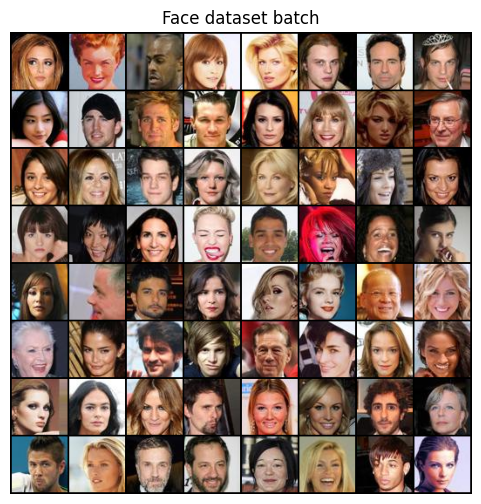

In [6]:
images, _ = next(iter(loader))
print("Batch shape:", images.shape)
print("Min:", images.min().item(), "Max:", images.max().item())

show_grid(images[:64], title="Face dataset batch", nrow=8)


In [7]:
import torch
import torch.nn as nn
from torch.nn.utils import spectral_norm

z_dim = 128
feat = 64
img_channels = 3


class FaceGenerator(nn.Module):
    def __init__(self, z_dim=128, feat=64, img_channels=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, feat * 8, 4, 1, 0, bias=False),    # 1 -> 4
            nn.BatchNorm2d(feat * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat * 8, feat * 4, 4, 2, 1, bias=False), # 4 -> 8
            nn.BatchNorm2d(feat * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat * 4, feat * 2, 4, 2, 1, bias=False), # 8 -> 16
            nn.BatchNorm2d(feat * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat * 2, feat, 4, 2, 1, bias=False),     # 16 -> 32
            nn.BatchNorm2d(feat),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat, img_channels, 4, 2, 1, bias=False), # 32 -> 64
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


class FaceDiscriminator(nn.Module):
    def __init__(self, img_channels=3, feat=64):
        super().__init__()
        self.net = nn.Sequential(
            spectral_norm(nn.Conv2d(img_channels, feat, 4, 2, 1, bias=False)),      # 64 -> 32
            nn.LeakyReLU(0.2, inplace=True),

            spectral_norm(nn.Conv2d(feat, feat * 2, 4, 2, 1, bias=False)),           # 32 -> 16
            nn.LeakyReLU(0.2, inplace=True),

            spectral_norm(nn.Conv2d(feat * 2, feat * 4, 4, 2, 1, bias=False)),       # 16 -> 8
            nn.LeakyReLU(0.2, inplace=True),

            spectral_norm(nn.Conv2d(feat * 4, feat * 8, 4, 2, 1, bias=False)),       # 8 -> 4
            nn.LeakyReLU(0.2, inplace=True),

            spectral_norm(nn.Conv2d(feat * 8, 1, 4, 1, 0, bias=False))               # 4 -> 1
        )

    def forward(self, x):
        return self.net(x).view(-1)


In [8]:
import torch.optim as optim

G = FaceGenerator(z_dim=z_dim, feat=feat, img_channels=img_channels).to(device)
D = FaceDiscriminator(img_channels=img_channels, feat=feat).to(device)

G.apply(dcgan_weights_init)

g_opt = optim.Adam(G.parameters(), lr=1e-4, betas=(0.0, 0.9))
d_opt = optim.Adam(D.parameters(), lr=1e-4, betas=(0.0, 0.9))

fixed_z = torch.randn(64, z_dim, 1, 1, device=device)

print("Generator params:", sum(p.numel() for p in G.parameters()))
print("Discriminator params:", sum(p.numel() for p in D.parameters()))


Generator params: 3806080
Discriminator params: 2763776


In [9]:
from tqdm import tqdm
from pathlib import Path

def latest_ckpt(models_dir: Path):
    ckpts = sorted(models_dir.glob("ckpt_epoch_*.pth"))
    if not ckpts:
        return None
    return ckpts[-1]


In [10]:
ckpt_path = latest_ckpt(paths.models_dir)

resume_old_generator = True
start_epoch = 1
base_epoch = 0

if ckpt_path is not None and resume_old_generator:
    print("Loading checkpoint:", ckpt_path)
    ckpt = torch.load(ckpt_path, map_location=device)

    # load only Generator because discriminator architecture changed
    G.load_state_dict(ckpt["G"])
    print("Loaded old Generator weights successfully.")

    base_epoch = ckpt.get("epoch", 0)
    print("Old checkpoint epoch:", base_epoch)

    print("Skipping Discriminator checkpoint load because architecture changed.")
    print("Skipping optimizer checkpoint load because optimizer state no longer matches.")
else:
    print("No checkpoint loaded. Starting fresh.")


Loading checkpoint: D:\Projects\GANs\experiments\10_face_does_not_exist\models\ckpt_epoch_050.pth
Loaded old Generator weights successfully.
Old checkpoint epoch: 50
Skipping Discriminator checkpoint load because architecture changed.
Skipping optimizer checkpoint load because optimizer state no longer matches.


In [11]:
extra_epochs = 200
end_epoch = base_epoch + extra_epochs

print(f"Training from epoch {base_epoch + 1} to {end_epoch}")


Training from epoch 51 to 250


In [17]:
import torch.nn.functional as F

for epoch in range(base_epoch + 1, end_epoch + 1):
    G.train()
    D.train()

    pbar = tqdm(loader, desc=f"Face HingeGAN Epoch {epoch}/{end_epoch}")

    for real, _ in pbar:
        real = real.to(device, non_blocking=True)
        b = real.size(0)

        # -------------------------
        # Train Discriminator
        # -------------------------
        z = torch.randn(b, z_dim, 1, 1, device=device)
        fake = G(z).detach()

        d_real = D(real)
        d_fake = D(fake)

        d_loss_real = F.relu(1.0 - d_real).mean()
        d_loss_fake = F.relu(1.0 + d_fake).mean()
        d_loss = d_loss_real + d_loss_fake

        d_opt.zero_grad(set_to_none=True)
        d_loss.backward()
        d_opt.step()

        # -------------------------
        # Train Generator
        # -------------------------
        z = torch.randn(b, z_dim, 1, 1, device=device)
        fake = G(z)
        d_fake_for_g = D(fake)

        g_loss = -d_fake_for_g.mean()

        g_opt.zero_grad(set_to_none=True)
        g_loss.backward()
        g_opt.step()

        pbar.set_postfix(
            d_loss=float(d_loss.item()),
            g_loss=float(g_loss.item())
        )

    G.eval()
    with torch.no_grad():
        samples = G(fixed_z)

    save_grid(
        samples,
        paths.samples_dir / f"epoch_{epoch:03d}.png",
        nrow=8
    )

    torch.save({
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "g_opt": g_opt.state_dict(),
        "d_opt": d_opt.state_dict(),
        "z_dim": z_dim,
        "feat": feat,
        "img_channels": img_channels,
        "img_size": IMG_SIZE
    }, paths.models_dir / f"ckpt_epoch_{epoch:03d}.pth")

    print(
        f"[10_face_does_not_exist | HingeGAN] "
        f"Epoch {epoch}/{end_epoch} | d_loss={d_loss.item():.4f} | g_loss={g_loss.item():.4f}"
    )


Face HingeGAN Epoch 51/250: 100%|██████████| 1583/1583 [02:47<00:00,  9.43it/s, d_loss=1.76, g_loss=-0.676]  


[10_face_does_not_exist | HingeGAN] Epoch 51/250 | d_loss=1.7630 | g_loss=-0.6762


Face HingeGAN Epoch 52/250: 100%|██████████| 1583/1583 [02:26<00:00, 10.81it/s, d_loss=1.85, g_loss=-0.0438] 


[10_face_does_not_exist | HingeGAN] Epoch 52/250 | d_loss=1.8505 | g_loss=-0.0438


Face HingeGAN Epoch 53/250: 100%|██████████| 1583/1583 [02:13<00:00, 11.85it/s, d_loss=1.78, g_loss=-0.572]   


[10_face_does_not_exist | HingeGAN] Epoch 53/250 | d_loss=1.7806 | g_loss=-0.5720


Face HingeGAN Epoch 54/250:  89%|████████▉ | 1410/1583 [02:03<00:15, 11.46it/s, d_loss=1.77, g_loss=-0.517]  


KeyboardInterrupt: 

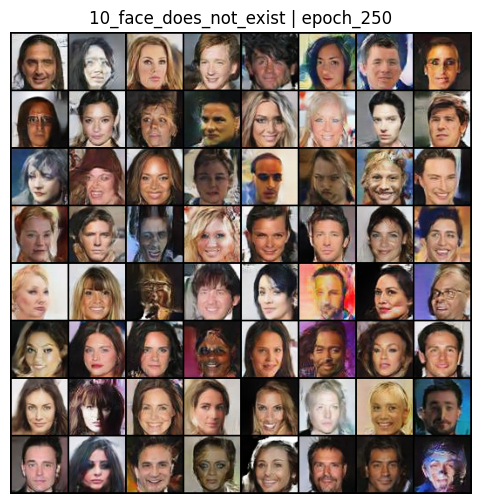

In [14]:
G.eval()
with torch.no_grad():
    samples = G(fixed_z)

show_grid(samples, title=f"10_face_does_not_exist | epoch_{end_epoch:03d}", nrow=8)


In [15]:
# Optional: lower LR later if training becomes unstable
for param_group in g_opt.param_groups:
    param_group["lr"] = 1e-4

for param_group in d_opt.param_groups:
    param_group["lr"] = 1e-4

print("Updated G LR:", g_opt.param_groups[0]["lr"])
print("Updated D LR:", d_opt.param_groups[0]["lr"])


Updated G LR: 0.0001
Updated D LR: 0.0001


In [16]:
# Optional: save one final sample grid with a fixed name
save_grid(samples, paths.exp_dir / "latest_face_samples.png", nrow=8)
paths.exp_dir / "latest_face_samples.png"


WindowsPath('D:/Projects/GANs/experiments/10_face_does_not_exist/latest_face_samples.png')